# Diabetes Disease Progression Regression Study
ML Assignment: Understanding the data, EDA, adding a few useful features, comparing models, checking the final errors, and answering the main questions from the assignment.

## 1. Problem Statement and Evaluation Goal

The target variable is a continuous disease progression score, so this is a regression problem. In simple terms, the aim is to learn a function like:

```text
f(X) -> y_hat
```

Here, `X` contains the 10 baseline measurements, and `y_hat` is the predicted disease progression value.

We have used the following research questions from the assignment as the main guide for the analysis:

1. Which baseline characteristics have the strongest statistical association with disease progression?
2. How well can a linear model explain the variation in the target?
3. Does regularization improve generalization when predictors are correlated?
4. Do nonlinear models capture relationships that a linear model cannot?
5. How sensitive are the conclusions to the choice of model?
6. Which model provides the best balance between predictive accuracy and interpretability?

The direct answers are given in Section 13, after the EDA, feature engineering, model comparison, and diagnostics.

In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from scipy import stats

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT

pd.set_option("display.max_columns", 120)
pd.set_option("display.precision", 4)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {
    "teal": "#0B7285",
    "amber": "#F08C00",
    "indigo": "#5C7CFA",
    "green": "#2B8A3E",
    "red": "#C92A2A",
    "violet": "#862E9C",
    "gray": "#495057",
    "light": "#F8F9FA",
}

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.titlesize": 13,
    "font.size": 10,
    "legend.frameon": False,
})


def tidy_number(value, digits=4):
    if isinstance(value, (np.floating, float)):
        return round(float(value), digits)
    if isinstance(value, (np.integer, int)):
        return int(value)
    return value


## 2. Loading Diabetes Dataset and Data Dictionary

We are using the `load_diabetes` dataset from scikit-learn. It has 442 observations and 10 baseline variables. The variables in this dataset are already centered and scaled, but we still use scaling inside the model pipelines so that the same approach also works properly after feature engineering.

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

feature_descriptions = {
    "age": "Age",
    "sex": "Sex indicator",
    "bmi": "Body mass index",
    "bp": "Average blood pressure",
    "s1": "Total serum cholesterol",
    "s2": "Low-density lipoproteins",
    "s3": "High-density lipoproteins",
    "s4": "Total cholesterol / HDL ratio",
    "s5": "Log serum triglycerides",
    "s6": "Blood sugar level",
}

data_dictionary = pd.DataFrame({
    "feature": list(feature_descriptions.keys()),
    "meaning": list(feature_descriptions.values()),
    "role": ["Predictor"] * len(feature_descriptions),
})

dataset_audit = pd.DataFrame({
    "item": [
        "Number of observations",
        "Number of original predictors",
        "Missing values in predictors",
        "Missing values in target",
        "Target mean",
        "Target standard deviation",
        "Target minimum",
        "Target maximum",
    ],
    "value": [
        X.shape[0],
        X.shape[1],
        int(X.isna().sum().sum()),
        int(y.isna().sum()),
        float(y.mean()),
        float(y.std()),
        float(y.min()),
        float(y.max()),
    ],
})

display(data_dictionary)
display(dataset_audit)
display(X.head())

,feature,meaning,role
0,age,Age,Predictor
1,sex,Sex indicator,Predictor
2,bmi,Body mass index,Predictor
3,bp,Average blood pressure,Predictor
4,s1,Total serum cholesterol,Predictor
5,s2,Low-density lipoproteins,Predictor
6,s3,High-density lipoproteins,Predictor
7,s4,Total cholesterol / HDL ratio,Predictor
8,s5,Log serum triglycerides,Predictor
9,s6,Blood sugar level,Predictor


,item,value
0,Number of observations,442.0000
1,Number of original predictors,10.0000
2,Missing values in predictors,0.0000
3,Missing values in target,0.0000
4,Target mean,152.1335
5,Target standard deviation,77.0930
6,Target minimum,25.0000
7,Target maximum,346.0000


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466


## 3. Data Quality and Summary Statistics

Before fitting models, we first check the basic details of the data: number of rows and columns, missing values, summary statistics, and the range of the target. This gives a better idea of the scale of the prediction problem before looking at RMSE or MAE.

,count,mean,std,min,25%,50%,75%,max,missing,target_correlation
bmi,442.0,-2.2456e-16,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706,0,0.5865
s5,442.0,9.2686e-17,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336,0,0.5659
bp,442.0,-4.7976e-17,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320,0,0.4415
s4,442.0,-9.0425e-18,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852,0,0.4305
s3,442.0,-5.7772e-18,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812,0,-0.3948
s6,442.0,1.1303e-17,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356,0,0.3825
s1,442.0,-1.3815e-17,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539,0,0.2120
age,442.0,-2.5118e-19,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107,0,0.1879
s2,442.0,3.9184e-17,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988,0,0.1741
sex,442.0,1.2308e-17,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507,0,0.0431


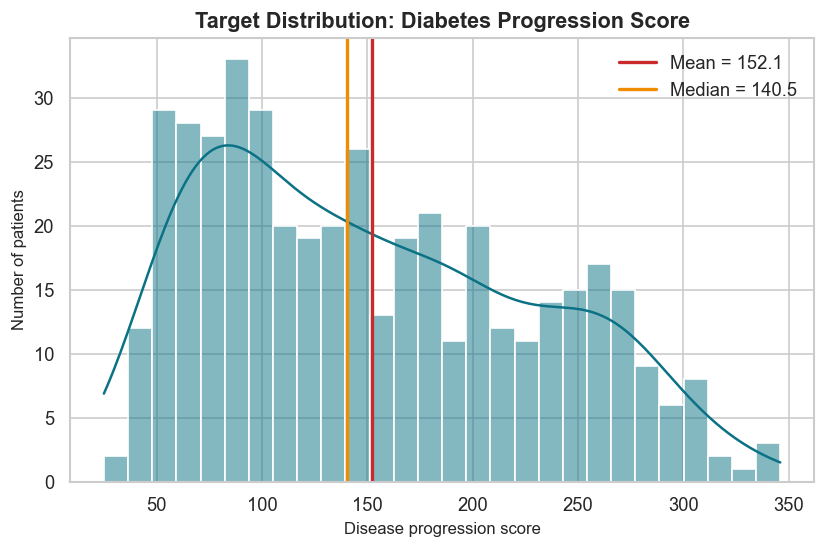

In [3]:
summary_stats = X.describe().T
summary_stats["missing"] = X.isna().sum()
summary_stats["target_correlation"] = X.corrwith(y).round(4)
summary_stats = summary_stats.sort_values("target_correlation", key=lambda s: s.abs(), ascending=False)
display(summary_stats)

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(y, bins=28, kde=True, ax=ax, color=PALETTE["teal"], edgecolor="white")
ax.axvline(y.mean(), color=PALETTE["red"], linewidth=2, label=f"Mean = {y.mean():.1f}")
ax.axvline(y.median(), color=PALETTE["amber"], linewidth=2, label=f"Median = {y.median():.1f}")
ax.set_title("Target Distribution: Diabetes Progression Score")
ax.set_xlabel("Disease progression score")
ax.set_ylabel("Number of patients")
ax.legend()
plt.show()

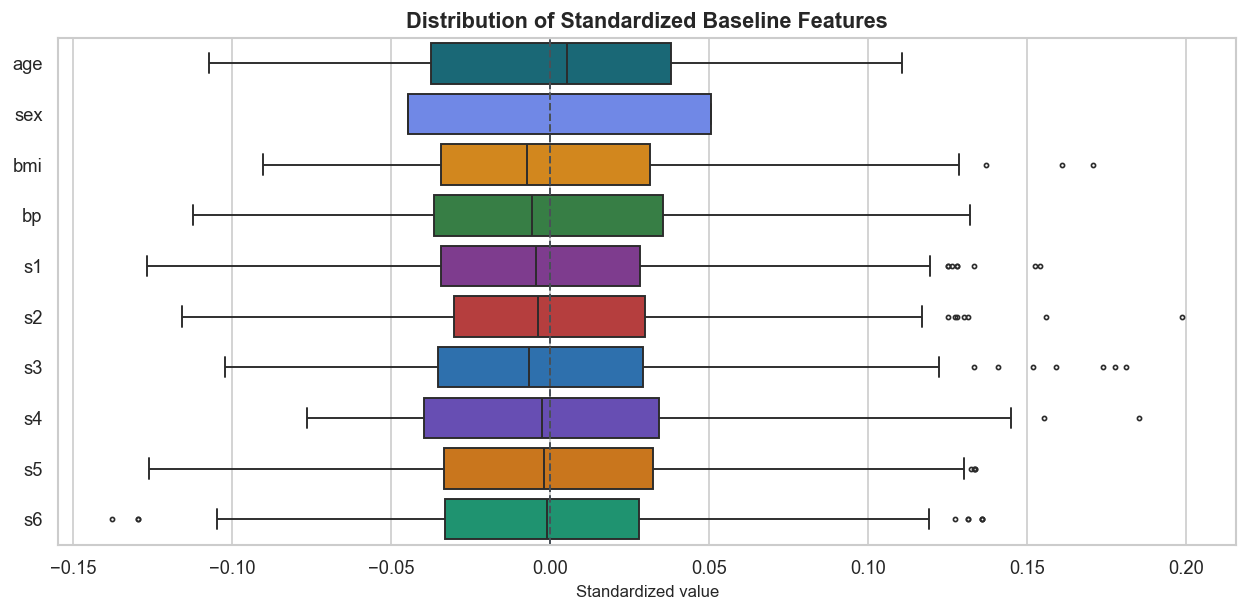

In [4]:
feature_long = X.melt(var_name="feature", value_name="standardized_value")

feature_box_palette = [
    PALETTE["teal"],
    PALETTE["indigo"],
    PALETTE["amber"],
    PALETTE["green"],
    PALETTE["violet"],
    PALETTE["red"],
    "#1971C2",
    "#5F3DC4",
    "#E67700",
    "#0CA678",
]

fig, ax = plt.subplots(figsize=(10.5, 5.2))
sns.boxplot(
    data=feature_long,
    x="standardized_value",
    y="feature",
    hue="feature",
    palette=feature_box_palette,
    legend=False,
    ax=ax,
    fliersize=2.5,
    linewidth=1.15,
)
ax.axvline(0, color=PALETTE["gray"], linewidth=1.2, linestyle="--")
ax.set_title("Distribution of Standardized Baseline Features")
ax.set_xlabel("Standardized value")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 4. Exploratory Data Analysis

In this part, we mainly look at two things:

- How each feature is related to the target.
- How the features are related to each other.

This is useful because strong feature-target relationships help prediction, while strong feature-feature relationships can create multicollinearity problems.

,pearson_correlation_with_target
bmi,0.5865
s5,0.5659
bp,0.4415
s4,0.4305
s3,-0.3948
s6,0.3825
s1,0.2120
age,0.1879
s2,0.1741
sex,0.0431


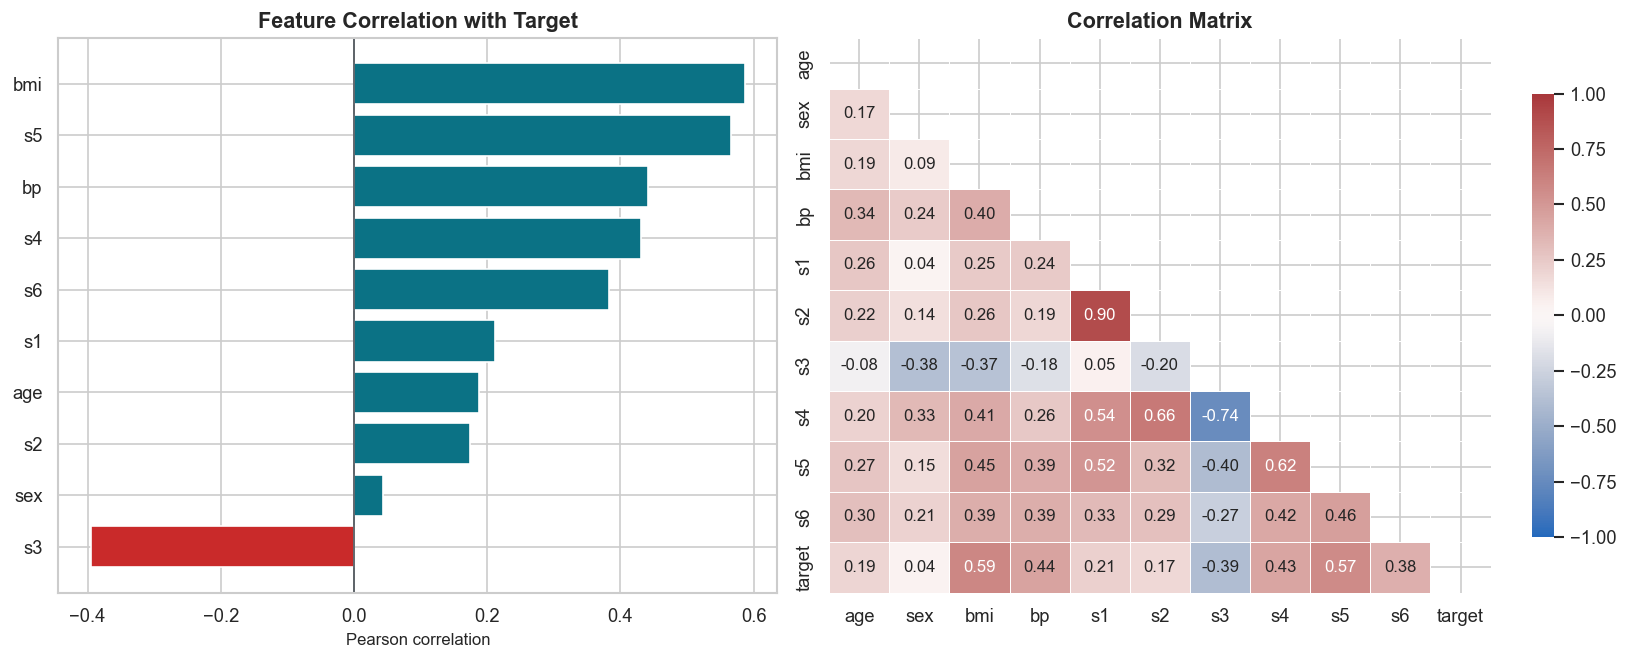

In [5]:
eda_df = X.copy()
eda_df["target"] = y

corr = eda_df.corr()
corr_with_target = corr["target"].drop("target").sort_values(key=lambda s: s.abs(), ascending=False)
display(corr_with_target.to_frame("pearson_correlation_with_target"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.15]})

corr_plot = corr_with_target.sort_values()
colors = [PALETTE["red"] if value < 0 else PALETTE["teal"] for value in corr_plot]
axes[0].barh(corr_plot.index, corr_plot.values, color=colors)
axes[0].axvline(0, color=PALETTE["gray"], linewidth=1)
axes[0].set_title("Feature Correlation with Target")
axes[0].set_xlabel("Pearson correlation")
axes[0].set_ylabel("")

mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mask,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=axes[1],
)
axes[1].set_title("Correlation Matrix")
plt.tight_layout()
plt.show()

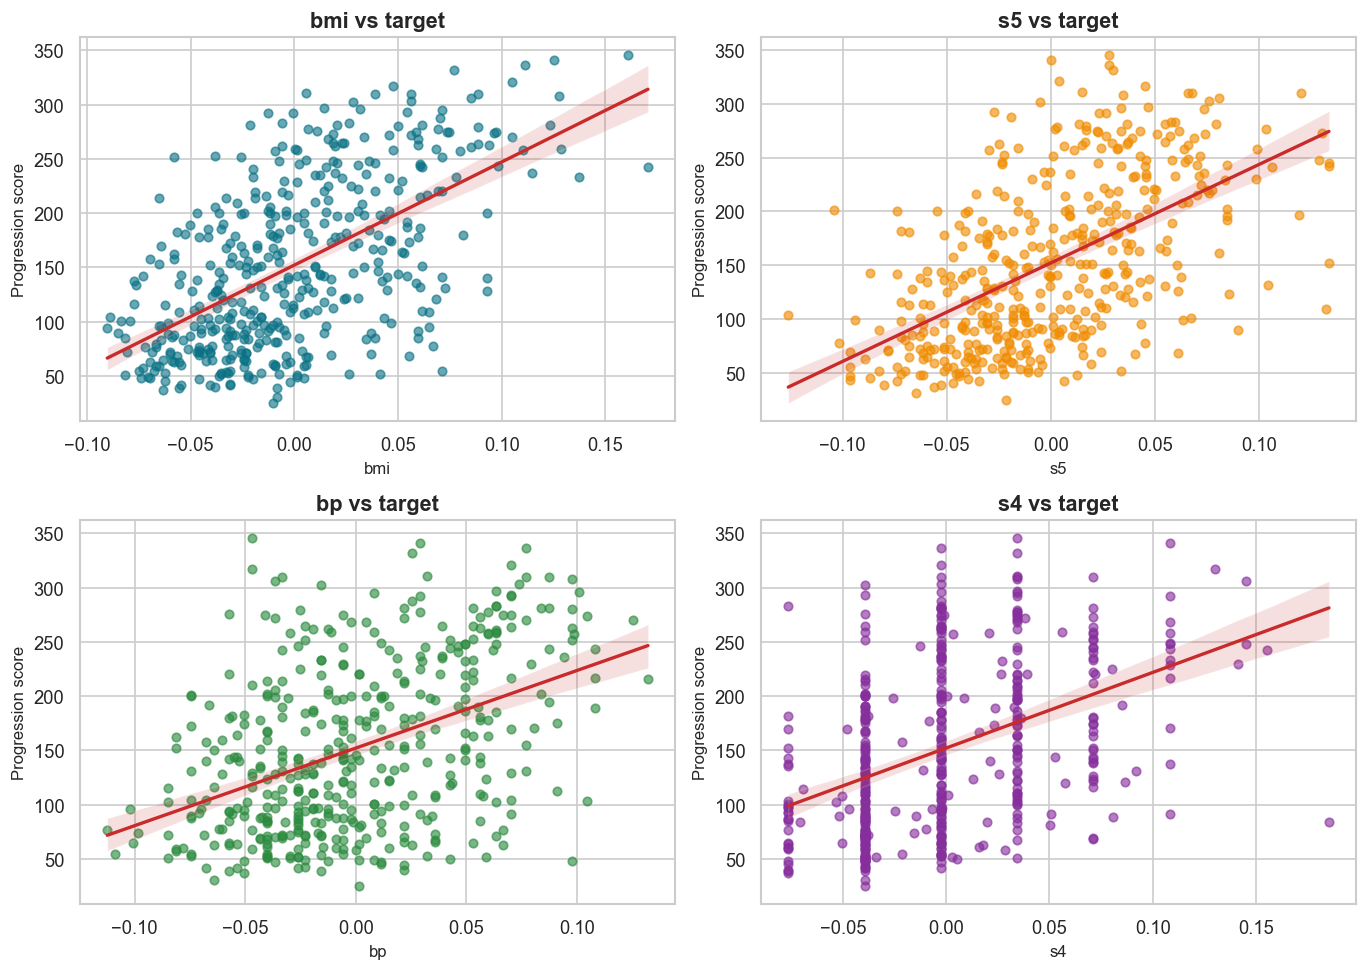

In [6]:
top_features = corr_with_target.abs().head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))
axes = axes.ravel()
for ax, feature, color in zip(axes, top_features, [PALETTE["teal"], PALETTE["amber"], PALETTE["green"], PALETTE["violet"]]):
    sns.regplot(
        x=X[feature],
        y=y,
        ax=ax,
        scatter_kws={"alpha": 0.62, "s": 26, "color": color},
        line_kws={"color": PALETTE["red"], "linewidth": 2},
        ci=95,
    )
    ax.set_title(f"{feature} vs target")
    ax.set_xlabel(feature)
    ax.set_ylabel("Progression score")
plt.tight_layout()
plt.show()

## 5. Multicollinearity Check

Some of the serum measurements are closely related, so multicollinearity is expected. We use Variance Inflation Factor (VIF) to see how much one predictor can be explained by the other predictors. If VIF is high, it is a sign that Ridge or Lasso may be more stable than plain OLS.

,feature,r2_from_other_features,VIF
0,s1,0.9831,59.2025
1,s2,0.9745,39.1934
2,s3,0.9351,15.4022
3,s5,0.9008,10.0760
4,s4,0.8875,8.8910
5,bmi,0.3375,1.5094
6,s6,0.3264,1.4846
7,bp,0.3148,1.4594
8,sex,0.2176,1.2781
9,age,0.1785,1.2173


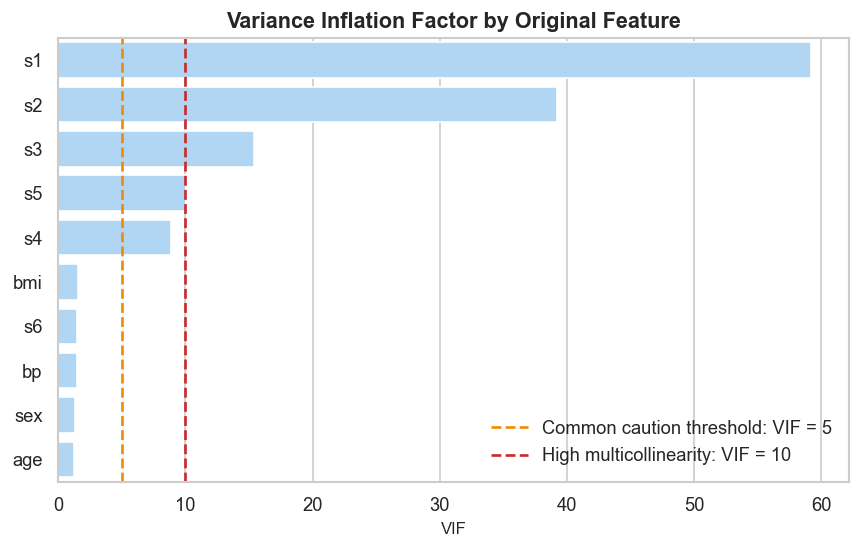

In [7]:
def calculate_vif(df):
    rows = []
    for feature in df.columns:
        other_features = [col for col in df.columns if col != feature]
        model = LinearRegression()
        model.fit(df[other_features], df[feature])
        r2 = model.score(df[other_features], df[feature])
        vif = np.inf if r2 >= 0.999999 else 1.0 / (1.0 - r2)
        rows.append({"feature": feature, "r2_from_other_features": r2, "VIF": vif})
    return pd.DataFrame(rows).sort_values("VIF", ascending=False).reset_index(drop=True)


vif_table = calculate_vif(X)
display(vif_table)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
sns.barplot(data=vif_table, x="VIF", y="feature", ax=ax, color="#A5D8FF")
ax.axvline(5, color=PALETTE["amber"], linestyle="--", linewidth=1.6, label="Common caution threshold: VIF = 5")
ax.axvline(10, color=PALETTE["red"], linestyle="--", linewidth=1.6, label="High multicollinearity: VIF = 10")
ax.set_title("Variance Inflation Factor by Original Feature")
ax.set_xlabel("VIF")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.show()

## 6. Feature Engineering Strategy

For feature engineering, we have kept the extra features simple and interpretable first, and then we also add polynomial features to fully cover the usecase requirement. The manually added features include:

- Squared terms such as `bmi_squared`, `bp_squared`, and `s5_squared` to allow simple nonlinear effects.
- Interaction terms such as BMI with blood pressure, BMI with triglycerides, and blood pressure with triglycerides.
- A few combined lipid/metabolic features that may capture risk better than a single variable.

After this, we also compare polynomial feature sets of degree 2 and degree 3. This covers terms such as `x_i^2`, `x_i^3`, and interaction terms like `x_i x_j`. For each expanded feature setting, we compare OLS, Ridge, and Lasso so that the effect of feature engineering, model complexity, and regularization can be seen clearly.

All these features are created only from the input variables, so there is no leakage from the target.

In [8]:
def add_engineered_features(df):
    engineered = df.copy()
    engineered["bmi_squared"] = engineered["bmi"] ** 2
    engineered["bp_squared"] = engineered["bp"] ** 2
    engineered["s5_squared"] = engineered["s5"] ** 2
    engineered["bmi_x_bp"] = engineered["bmi"] * engineered["bp"]
    engineered["bmi_x_s5"] = engineered["bmi"] * engineered["s5"]
    engineered["bp_x_s5"] = engineered["bp"] * engineered["s5"]
    engineered["s3_x_s4"] = engineered["s3"] * engineered["s4"]
    engineered["lipid_balance_s1_minus_s3"] = engineered["s1"] - engineered["s3"]
    engineered["metabolic_risk_index"] = engineered[["bmi", "bp", "s5", "s6"]].mean(axis=1)
    return engineered


engineered_feature_guide = pd.DataFrame({
    "engineered_feature": [
        "bmi_squared",
        "bp_squared",
        "s5_squared",
        "bmi_x_bp",
        "bmi_x_s5",
        "bp_x_s5",
        "s3_x_s4",
        "lipid_balance_s1_minus_s3",
        "metabolic_risk_index",
    ],
    "reason": [
        "Allows a curved BMI-progress relationship.",
        "Allows nonlinear blood pressure effect.",
        "Allows nonlinear triglyceride-related effect.",
        "Captures joint BMI and blood pressure burden.",
        "Captures joint BMI and triglyceride burden.",
        "Captures combined blood pressure and triglyceride signal.",
        "Represents interaction between HDL and cholesterol ratio proxy.",
        "Contrasts total cholesterol proxy with HDL proxy.",
        "Compact average of BMI, blood pressure, triglycerides, and blood sugar.",
    ],
})
display(engineered_feature_guide)

,engineered_feature,reason
0,bmi_squared,Allows a curved BMI-progress relationship.
1,bp_squared,Allows nonlinear blood pressure effect.
2,s5_squared,Allows nonlinear triglyceride-related effect.
3,bmi_x_bp,Captures joint BMI and blood pressure burden.
4,bmi_x_s5,Captures joint BMI and triglyceride burden.
5,bp_x_s5,Captures combined blood pressure and triglycer...
6,s3_x_s4,Represents interaction between HDL and cholest...
7,lipid_balance_s1_minus_s3,Contrasts total cholesterol proxy with HDL proxy.
8,metabolic_risk_index,"Compact average of BMI, blood pressure, trigly..."


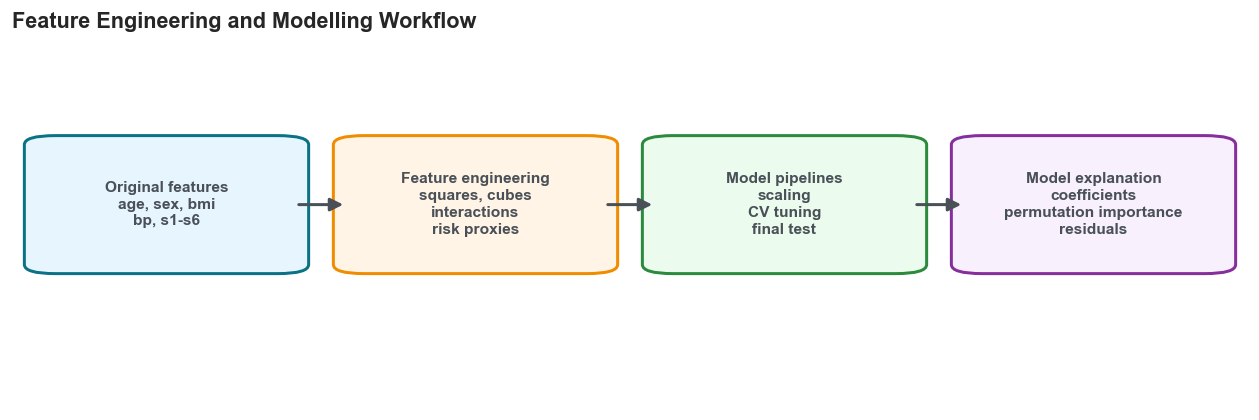

In [9]:
fig, ax = plt.subplots(figsize=(10.6, 3.6))
ax.set_axis_off()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

workflow_nodes = [
    {
        "text": "Original features\nage, sex, bmi\nbp, s1-s6",
        "xy": (0.03, 0.39),
        "color": PALETTE["teal"],
        "fill": "#E7F5FF",
    },
    {
        "text": "Feature engineering\nsquares, cubes\ninteractions\nrisk proxies",
        "xy": (0.28, 0.39),
        "color": PALETTE["amber"],
        "fill": "#FFF4E6",
    },
    {
        "text": "Model pipelines\nscaling\nCV tuning\nfinal test",
        "xy": (0.53, 0.39),
        "color": PALETTE["green"],
        "fill": "#EBFCEE",
    },
    {
        "text": "Model explanation\ncoefficients\npermutation importance\nresiduals",
        "xy": (0.78, 0.39),
        "color": PALETTE["violet"],
        "fill": "#F8F0FC",
    },
]

box_width = 0.19
box_height = 0.34

for node in workflow_nodes:
    x0, y0 = node["xy"]
    patch = FancyBboxPatch(
        (x0, y0),
        box_width,
        box_height,
        boxstyle="round,pad=0.02,rounding_size=0.025",
        linewidth=1.8,
        edgecolor=node["color"],
        facecolor=node["fill"],
    )
    ax.add_patch(patch)
    ax.text(
        x0 + box_width / 2,
        y0 + box_height / 2,
        node["text"],
        ha="center",
        va="center",
        fontsize=9.3,
        color=PALETTE["gray"],
        weight="bold",
        linespacing=1.25,
    )

arrow_y = 0.56
for left_node, right_node in zip(workflow_nodes[:-1], workflow_nodes[1:]):
    start_x = left_node["xy"][0] + box_width + 0.012
    end_x = right_node["xy"][0] - 0.012
    ax.add_patch(
        FancyArrowPatch(
            (start_x, arrow_y),
            (end_x, arrow_y),
            arrowstyle="-|>",
            mutation_scale=16,
            linewidth=1.8,
            color=PALETTE["gray"],
            shrinkA=0,
            shrinkB=0,
        )
    )

ax.set_title("Feature Engineering and Modelling Workflow", loc="left", pad=10, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

,feature,correlation_with_target
0,metabolic_risk_index,0.6603
1,bmi,0.5865
2,s5,0.5659
3,bp,0.4415
4,lipid_balance_s1_minus_s3,0.4406
5,s4,0.4305
6,s3,-0.3948
7,s6,0.3825
8,bmi_squared,0.2526
9,s1,0.2120


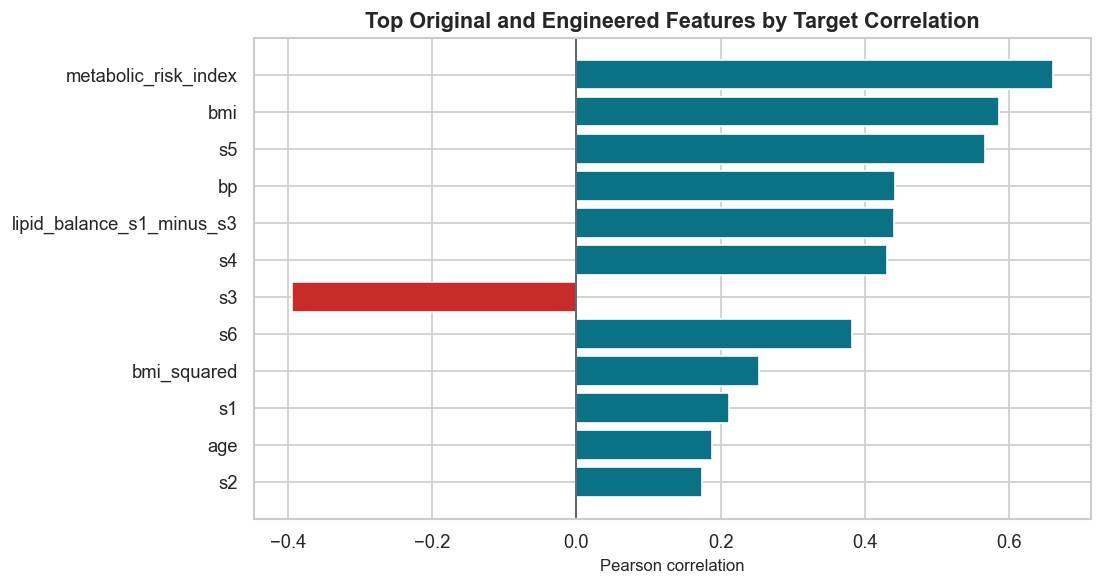

In [10]:
X_engineered = add_engineered_features(X)
engineered_corr = (
    X_engineered.corrwith(y)
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .to_frame("correlation_with_target")
    .reset_index()
    .rename(columns={"index": "feature"})
)

display(engineered_corr.head(15))

fig, ax = plt.subplots(figsize=(9, 5.2))
plot_df = engineered_corr.head(12).iloc[::-1]
colors = [PALETTE["red"] if value < 0 else PALETTE["teal"] for value in plot_df["correlation_with_target"]]
ax.barh(plot_df["feature"], plot_df["correlation_with_target"], color=colors)
ax.axvline(0, color=PALETTE["gray"], linewidth=1)
ax.set_title("Top Original and Engineered Features by Target Correlation")
ax.set_xlabel("Pearson correlation")
ax.set_ylabel("")
plt.show()

## 7. Train-Test Split and Modelling Protocol

We keep a separate test set for the final evaluation. Model selection and hyperparameter tuning are done only on the training set using 5-fold cross-validation.

This is important because using the test set repeatedly for model selection would make the final performance look better than it really is.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_train_engineered = add_engineered_features(X_train)
X_test_engineered = add_engineered_features(X_test)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "subset": ["Training", "Test"],
    "rows": [len(X_train), len(X_test)],
    "share": [len(X_train) / len(X), len(X_test) / len(X)],
    "target_mean": [float(y_train.mean()), float(y_test.mean())],
    "target_std": [float(y_train.std()), float(y_test.std())],
})
display(split_summary)

,subset,rows,share,target_mean,target_std
0,Training,353,0.7986,153.7365,78.0619
1,Test,89,0.2014,145.7753,73.2008


In [12]:
def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def make_poly_pipeline(model, degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])


model_specs = {
    "DummyMean": {
        "feature_set": "original",
        "estimator": Pipeline([("model", DummyRegressor(strategy="mean"))]),
        "param_grid": {},
        "family": "baseline",
    },
    "OLS_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "param_grid": {},
        "family": "linear",
    },
    "Ridge_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Ridge(random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 3, 31)},
        "family": "regularized linear",
    },
    "Lasso_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=200000, random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 2, 31)},
        "family": "regularized linear",
    },
    "ElasticNet_original": {
        "feature_set": "original",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", ElasticNet(max_iter=200000, random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 1, 17), "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
        "family": "regularized linear",
    },
    "OLS_engineered": {
        "feature_set": "engineered",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "param_grid": {},
        "family": "feature engineered",
    },
    "Ridge_engineered": {
        "feature_set": "engineered",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Ridge(random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 4, 35)},
        "family": "feature engineered",
    },
    "Lasso_engineered": {
        "feature_set": "engineered",
        "estimator": Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=200000, random_state=RANDOM_STATE))]),
        "param_grid": {"model__alpha": np.logspace(-3, 2, 31)},
        "family": "feature engineered",
    },
    "OLS_poly2": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(LinearRegression(), degree=2),
        "param_grid": {},
        "family": "polynomial degree 2",
    },
    "Ridge_poly2": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Ridge(random_state=RANDOM_STATE), degree=2),
        "param_grid": {"model__alpha": np.logspace(-2, 5, 35)},
        "family": "polynomial degree 2",
    },
    "Lasso_poly2": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Lasso(max_iter=300000, random_state=RANDOM_STATE), degree=2),
        "param_grid": {"model__alpha": np.logspace(-3, 2, 31)},
        "family": "polynomial degree 2",
    },
    "OLS_poly3": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(LinearRegression(), degree=3),
        "param_grid": {},
        "family": "polynomial degree 3",
    },
    "Ridge_poly3": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Ridge(random_state=RANDOM_STATE), degree=3),
        "param_grid": {"model__alpha": np.logspace(-1, 6, 30)},
        "family": "polynomial degree 3",
    },
    "Lasso_poly3": {
        "feature_set": "original",
        "estimator": make_poly_pipeline(Lasso(max_iter=500000, random_state=RANDOM_STATE), degree=3),
        "param_grid": {"model__alpha": np.logspace(-2, 2, 25)},
        "family": "polynomial degree 3",
    },
    "RandomForest": {
        "feature_set": "original",
        "estimator": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
        "param_grid": {"n_estimators": [300], "max_depth": [2, 3, 4, None], "min_samples_leaf": [3, 5, 8]},
        "family": "nonlinear ensemble",
    },
    "GradientBoosting": {
        "feature_set": "original",
        "estimator": GradientBoostingRegressor(random_state=RANDOM_STATE),
        "param_grid": {"n_estimators": [80, 120, 180], "learning_rate": [0.03, 0.05, 0.08], "max_depth": [1, 2, 3], "subsample": [0.8, 1.0]},
        "family": "nonlinear ensemble",
    },
}

model_plan = pd.DataFrame([
    {
        "model": name,
        "family": spec["family"],
        "feature_set": spec["feature_set"],
        "hyperparameter_grid": str(spec["param_grid"]) if spec["param_grid"] else "None",
    }
    for name, spec in model_specs.items()
])
display(model_plan)

,model,family,feature_set,hyperparameter_grid
0,DummyMean,baseline,original,None
1,OLS_original,linear,original,None
2,Ridge_original,regularized linear,original,"{'model__alpha': array([1.00000000e-03, 1.5848..."
3,Lasso_original,regularized linear,original,"{'model__alpha': array([1.00000000e-03, 1.4677..."
4,ElasticNet_original,regularized linear,original,"{'model__alpha': array([1.00000000e-03, 1.7782..."
5,OLS_engineered,feature engineered,engineered,None
6,Ridge_engineered,feature engineered,engineered,"{'model__alpha': array([1.00000000e-03, 1.6065..."
7,Lasso_engineered,feature engineered,engineered,"{'model__alpha': array([1.00000000e-03, 1.4677..."
8,OLS_poly2,polynomial degree 2,original,None
9,Ridge_poly2,polynomial degree 2,original,"{'model__alpha': array([1.00000000e-02, 1.6065..."


## 8. Cross-Validated Model Selection

We use RMSE as the main metric because it is in the same units as the target and gives more penalty to large errors. We also report MAE and R2 so that the model performance can be understood from more than one angle.

In [13]:
def get_split_for_feature_set(feature_set):
    if feature_set == "engineered":
        return X_train_engineered, X_test_engineered
    return X_train, X_test


fitted_models = {}
cv_rows = []
test_rows = []

for name, spec in model_specs.items():
    X_train_used, X_test_used = get_split_for_feature_set(spec["feature_set"])
    grid = GridSearchCV(
        estimator=spec["estimator"],
        param_grid=spec["param_grid"],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    grid.fit(X_train_used, y_train)
    fitted_models[name] = grid

    best_index = grid.best_index_
    cv_rmse = -grid.best_score_
    train_rmse = -grid.cv_results_["mean_train_score"][best_index]
    cv_std = grid.cv_results_["std_test_score"][best_index]
    cv_rows.append({
        "model": name,
        "family": spec["family"],
        "feature_set": spec["feature_set"],
        "best_params": grid.best_params_,
        "cv_rmse_mean": cv_rmse,
        "cv_rmse_std": cv_std,
        "cv_train_rmse": train_rmse,
        "generalization_gap": cv_rmse - train_rmse,
    })

    y_pred = grid.best_estimator_.predict(X_test_used)
    test_rows.append({
        "model": name,
        "family": spec["family"],
        "feature_set": spec["feature_set"],
        "best_params": grid.best_params_,
        **regression_metrics(y_test, y_pred),
    })

cv_summary = pd.DataFrame(cv_rows).sort_values("cv_rmse_mean").reset_index(drop=True)
test_results = pd.DataFrame(test_rows).sort_values("RMSE").reset_index(drop=True)

display(cv_summary)
display(test_results)

,model,family,feature_set,best_params,cv_rmse_mean,cv_rmse_std,cv_train_rmse,generalization_gap
0,Lasso_original,regularized linear,original,{'model__alpha': 0.1467799267622069},55.3488,2.3480,53.4064,1.9424
1,ElasticNet_original,regularized linear,original,"{'model__alpha': 0.03162277660168379, 'model__...",55.3687,2.3688,53.3796,1.9891
2,Ridge_original,regularized linear,original,{'model__alpha': 1.0},55.3742,2.3732,53.3703,2.0039
3,OLS_original,linear,original,{},55.3946,2.3615,53.3461,2.0485
4,OLS_engineered,feature engineered,engineered,{},55.4160,2.5573,52.1128,3.3032
5,Ridge_engineered,feature engineered,engineered,{'model__alpha': 0.001},55.4162,2.5541,52.1128,3.3034
6,Lasso_engineered,feature engineered,engineered,{'model__alpha': 0.001},55.4217,2.5481,52.1129,3.3088
7,Lasso_poly2,polynomial degree 2,original,{'model__alpha': 3.1622776601683795},55.9712,1.9072,52.9185,3.0527
8,GradientBoosting,nonlinear ensemble,original,"{'learning_rate': 0.08, 'max_depth': 1, 'n_est...",56.6300,2.3023,46.4975,10.1325
9,Ridge_poly2,polynomial degree 2,original,{'model__alpha': 81.61400793251826},56.8867,1.6728,50.9885,5.8982


,model,family,feature_set,best_params,RMSE,MAE,R2
0,Lasso_poly2,polynomial degree 2,original,{'model__alpha': 3.1622776601683795},50.6853,41.2744,0.5151
1,Ridge_poly2,polynomial degree 2,original,{'model__alpha': 81.61400793251826},51.3381,41.1884,0.5025
2,GradientBoosting,nonlinear ensemble,original,"{'learning_rate': 0.08, 'max_depth': 1, 'n_est...",52.7024,41.6082,0.4758
3,Lasso_poly3,polynomial degree 3,original,{'model__alpha': 6.812920690579608},52.9417,43.8946,0.4710
4,Lasso_engineered,feature engineered,engineered,{'model__alpha': 0.001},53.0119,41.9639,0.4696
5,Ridge_engineered,feature engineered,engineered,{'model__alpha': 0.001},53.0131,41.9628,0.4696
6,OLS_engineered,feature engineered,engineered,{},53.0133,41.9611,0.4695
7,RandomForest,nonlinear ensemble,original,"{'max_depth': None, 'min_samples_leaf': 8, 'n_...",53.0500,42.7141,0.4688
8,Lasso_original,regularized linear,original,{'model__alpha': 0.1467799267622069},53.6857,42.8152,0.4560
9,ElasticNet_original,regularized linear,original,"{'model__alpha': 0.03162277660168379, 'model__...",53.7406,42.8146,0.4549


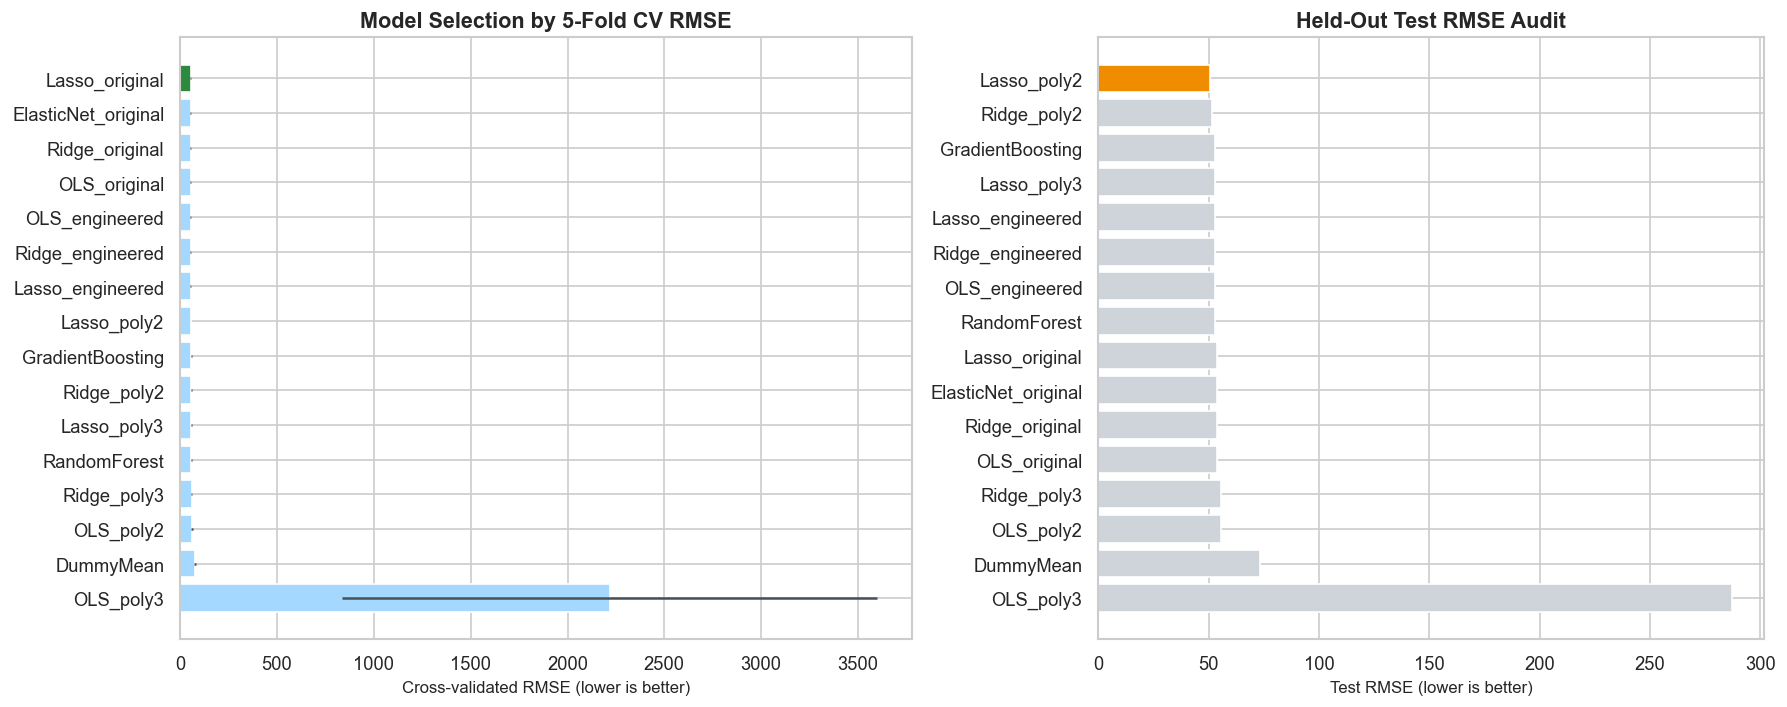


    **Honest selected model:** `Lasso_original` because it has the lowest training-set cross-validated RMSE.

    **Best held-out model in the audit table:** `Lasso_poly2`. This is reported transparently, but the model recommendation is based on cross-validation rather than test-set shopping.
    

In [14]:
selected_model_name = cv_summary.loc[0, "model"]
heldout_best_model_name = test_results.loc[0, "model"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.1, 1]})

cv_plot = cv_summary.sort_values("cv_rmse_mean", ascending=False)
axes[0].barh(
    cv_plot["model"],
    cv_plot["cv_rmse_mean"],
    xerr=cv_plot["cv_rmse_std"],
    color=[PALETTE["green"] if m == selected_model_name else "#A5D8FF" for m in cv_plot["model"]],
    ecolor=PALETTE["gray"],
)
axes[0].set_title("Model Selection by 5-Fold CV RMSE")
axes[0].set_xlabel("Cross-validated RMSE (lower is better)")
axes[0].set_ylabel("")

test_plot = test_results.sort_values("RMSE", ascending=False)
axes[1].barh(
    test_plot["model"],
    test_plot["RMSE"],
    color=[PALETTE["amber"] if m == heldout_best_model_name else "#CED4DA" for m in test_plot["model"]],
)
axes[1].set_title("Held-Out Test RMSE Audit")
axes[1].set_xlabel("Test RMSE (lower is better)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

display(Markdown(
    f"""
    **Honest selected model:** `{selected_model_name}` because it has the lowest training-set cross-validated RMSE.

    **Best held-out model in the audit table:** `{heldout_best_model_name}`. This is reported transparently, but the model recommendation is based on cross-validation rather than test-set shopping.
    """
))

## 9. Final Test Evaluation of the Selected Model

After choosing the model using cross-validation, we evaluate it once on the held-out test set. The diagnostic plots below are based on this selected model.

In [15]:
selected_spec = model_specs[selected_model_name]
selected_grid = fitted_models[selected_model_name]
X_train_selected, X_test_selected = get_split_for_feature_set(selected_spec["feature_set"])
y_pred_selected = selected_grid.best_estimator_.predict(X_test_selected)
selected_metrics = regression_metrics(y_test, y_pred_selected)

selected_result_table = pd.DataFrame([{
    "selected_model": selected_model_name,
    "feature_set": selected_spec["feature_set"],
    "best_params": selected_grid.best_params_,
    **selected_metrics,
}])
display(selected_result_table)

display(Markdown(
    f"""
    On the held-out test set, `{selected_model_name}` achieves **RMSE = {selected_metrics['RMSE']:.2f}**, **MAE = {selected_metrics['MAE']:.2f}**, and **R2 = {selected_metrics['R2']:.3f}**.
    """
))

,selected_model,feature_set,best_params,RMSE,MAE,R2
0,Lasso_original,original,{'model__alpha': 0.1467799267622069},53.6857,42.8152,0.456



    On the held-out test set, `Lasso_original` achieves **RMSE = 53.69**, **MAE = 42.82**, and **R2 = 0.456**.
    

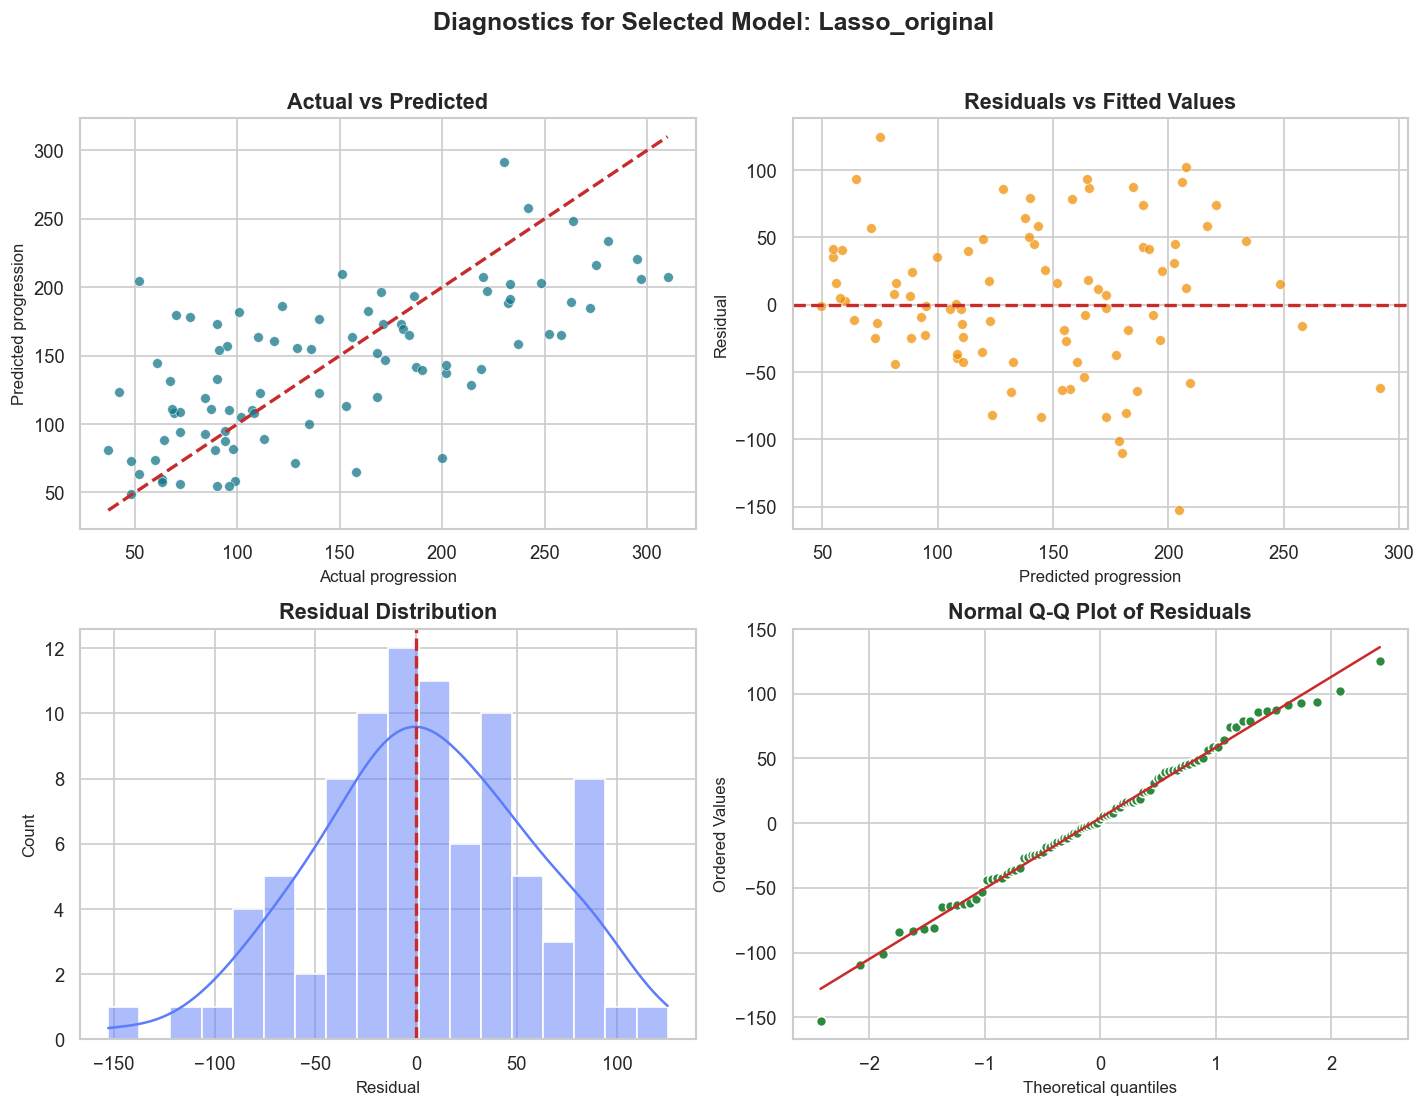

In [16]:
residuals = y_test - y_pred_selected

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()

lims = [
    min(float(y_test.min()), float(y_pred_selected.min())),
    max(float(y_test.max()), float(y_pred_selected.max())),
]
axes[0].scatter(y_test, y_pred_selected, alpha=0.72, s=34, color=PALETTE["teal"], edgecolor="white", linewidth=0.4)
axes[0].plot(lims, lims, color=PALETTE["red"], linestyle="--", linewidth=2)
axes[0].set_title("Actual vs Predicted")
axes[0].set_xlabel("Actual progression")
axes[0].set_ylabel("Predicted progression")

axes[1].scatter(y_pred_selected, residuals, alpha=0.72, s=34, color=PALETTE["amber"], edgecolor="white", linewidth=0.4)
axes[1].axhline(0, color=PALETTE["red"], linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs Fitted Values")
axes[1].set_xlabel("Predicted progression")
axes[1].set_ylabel("Residual")

sns.histplot(residuals, kde=True, bins=18, color=PALETTE["indigo"], edgecolor="white", ax=axes[2])
axes[2].axvline(0, color=PALETTE["red"], linestyle="--", linewidth=2)
axes[2].set_title("Residual Distribution")
axes[2].set_xlabel("Residual")
axes[2].set_ylabel("Count")

stats.probplot(residuals, dist="norm", plot=axes[3])
axes[3].get_lines()[0].set_markerfacecolor(PALETTE["green"])
axes[3].get_lines()[0].set_markeredgecolor("white")
axes[3].get_lines()[1].set_color(PALETTE["red"])
axes[3].set_title("Normal Q-Q Plot of Residuals")

fig.suptitle(f"Diagnostics for Selected Model: {selected_model_name}", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 10. Interpretability

For models with coefficients, we look at the coefficient values to understand which variables are contributing more. we also use permutation importance because it gives another view of feature importance and can be used across different model types.

,feature,coefficient,abs_coefficient
0,s5,28.6527,28.6527
1,s1,-27.0137,27.0137
2,bmi,25.9122,25.9122
3,bp,16.5911,16.5911
4,s2,11.2079,11.2079
5,sex,-11.1933,11.1933
6,s4,10.4001,10.4001
7,s6,2.3934,2.3934
8,age,1.6918,1.6918
9,s3,-0.0000,0.0000


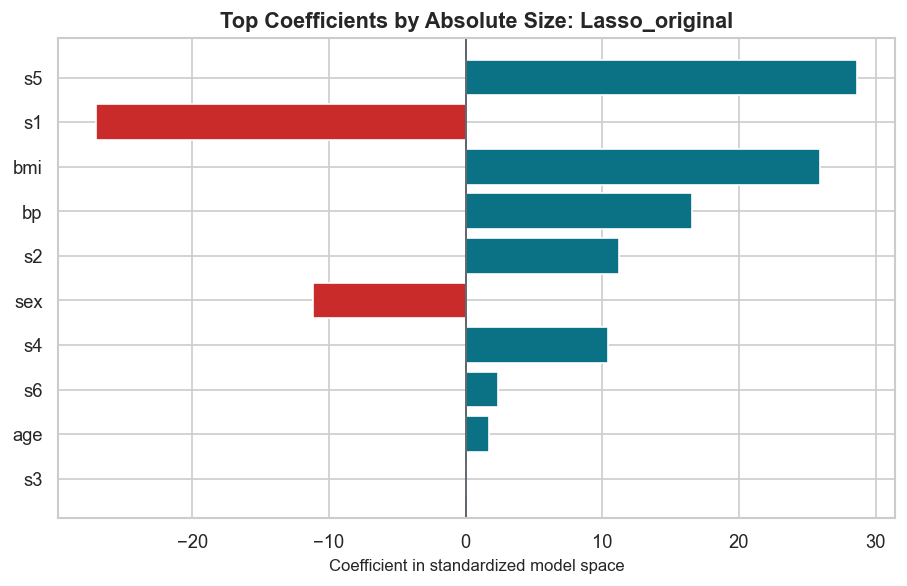

In [17]:
def feature_names_for_model(model_name):
    spec = model_specs[model_name]
    estimator = fitted_models[model_name].best_estimator_
    if spec["feature_set"] == "engineered":
        base_names = np.array(X_train_engineered.columns)
    else:
        base_names = np.array(X_train.columns)
    if isinstance(estimator, Pipeline) and "poly" in estimator.named_steps:
        return estimator.named_steps["poly"].get_feature_names_out(base_names)
    return base_names


def coefficient_table_for_model(model_name):
    estimator = fitted_models[model_name].best_estimator_
    model = estimator.named_steps["model"] if isinstance(estimator, Pipeline) and "model" in estimator.named_steps else estimator
    coefs = getattr(model, "coef_", None)
    if coefs is None:
        return None
    names = feature_names_for_model(model_name)
    return (
        pd.DataFrame({"feature": names, "coefficient": coefs})
        .assign(abs_coefficient=lambda df: df["coefficient"].abs())
        .sort_values("abs_coefficient", ascending=False)
        .reset_index(drop=True)
    )


selected_coef_table = coefficient_table_for_model(selected_model_name)
if selected_coef_table is not None:
    display(selected_coef_table.head(15))

    coef_plot_df = selected_coef_table.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 5.2))
    colors = [PALETTE["red"] if v < 0 else PALETTE["teal"] for v in coef_plot_df["coefficient"]]
    ax.barh(coef_plot_df["feature"], coef_plot_df["coefficient"], color=colors)
    ax.axvline(0, color=PALETTE["gray"], linewidth=1)
    ax.set_title(f"Top Coefficients by Absolute Size: {selected_model_name}")
    ax.set_xlabel("Coefficient in standardized model space")
    ax.set_ylabel("")
    plt.show()
else:
    display(Markdown(f"`{selected_model_name}` does not expose linear coefficients. Use permutation importance below."))

,feature,rmse_increase_when_permuted,std
0,s5,14.8618,2.7707
1,bmi,10.1089,2.5094
2,s1,8.3639,2.5045
3,sex,3.2553,1.0762
4,s2,3.0710,1.1154
5,bp,2.3060,1.9805
6,s4,1.0737,0.9328
7,s6,0.1721,0.1889
8,s3,0.0000,0.0000
9,age,-0.1843,0.2325


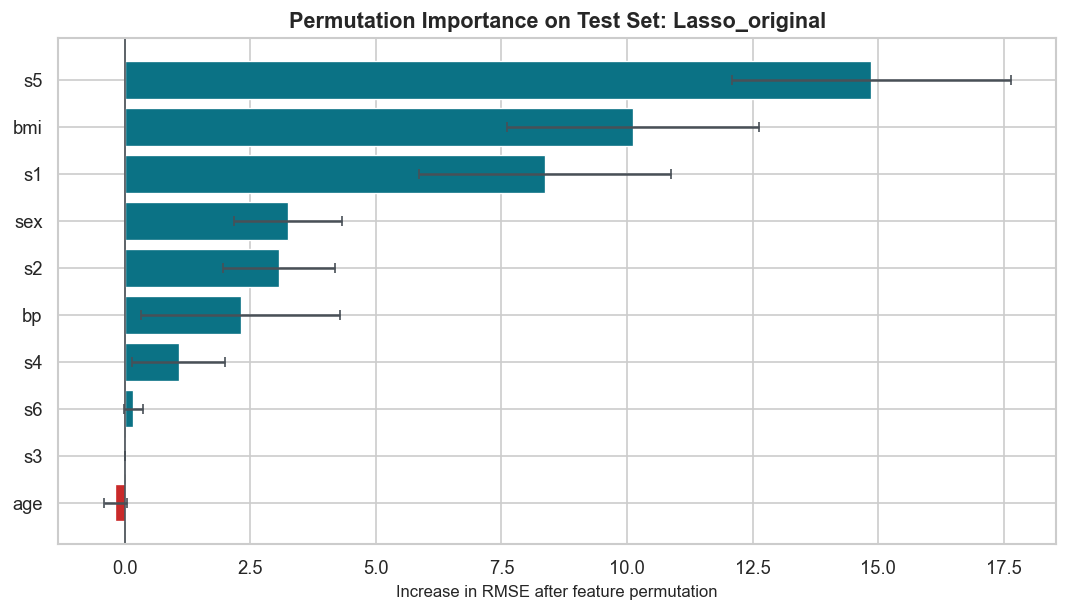

In [18]:
perm = permutation_importance(
    selected_grid.best_estimator_,
    X_test_selected,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

permutation_table = (
    pd.DataFrame({
        "feature": X_test_selected.columns,
        "rmse_increase_when_permuted": perm.importances_mean,
        "std": perm.importances_std,
    })
    .sort_values("rmse_increase_when_permuted", ascending=False)
    .reset_index(drop=True)
)
display(permutation_table.head(12))

fig, ax = plt.subplots(figsize=(9, 5.2))
perm_plot = permutation_table.head(10).iloc[::-1]
bar_colors = [
    PALETTE["red"] if value < 0 else PALETTE["teal"]
    for value in perm_plot["rmse_increase_when_permuted"]
]

ax.barh(
    perm_plot["feature"],
    perm_plot["rmse_increase_when_permuted"],
    color=bar_colors,
    edgecolor="white",
    linewidth=0.8,
)
ax.errorbar(
    perm_plot["rmse_increase_when_permuted"],
    perm_plot["feature"],
    xerr=perm_plot["std"],
    fmt="none",
    ecolor=PALETTE["gray"],
    elinewidth=1.5,
    capsize=3,
)
ax.axvline(0, color=PALETTE["gray"], linewidth=1)
ax.set_title(f"Permutation Importance on Test Set: {selected_model_name}")
ax.set_xlabel("Increase in RMSE after feature permutation")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 11. Error Analysis

Here we look at the largest prediction errors on the test set. Some large errors are expected because this is a small clinical dataset and many real-world factors affecting disease progression are not present in the data.

,actual,predicted,residual,absolute_error,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
56,52.0,204.7222,-152.7222,152.7222,-0.0418,-0.0446,0.0412,-0.0263,-0.0318,-0.0304,-0.0360,0.0029,0.0337,-0.0176
77,200.0,75.1038,124.8962,124.8962,-0.0963,-0.0446,-0.0364,-0.0745,-0.0387,-0.0276,0.0155,-0.0395,-0.0741,-0.0011
211,70.0,179.9936,-109.9936,109.9936,0.0926,-0.0446,0.0369,0.0219,-0.0250,-0.0167,0.0008,-0.0395,-0.0225,-0.0218
9,310.0,207.6979,102.3021,102.3021,-0.0709,-0.0446,0.0391,-0.0332,-0.0126,-0.0345,-0.0250,-0.0026,0.0677,-0.0135
209,77.0,178.4105,-101.4105,101.4105,0.0381,0.0507,-0.0181,0.0666,-0.0511,-0.0167,-0.0765,0.0343,-0.0119,-0.0135
131,158.0,64.6292,93.3708,93.3708,-0.0963,-0.0446,-0.0698,-0.0676,-0.0195,-0.0107,0.0155,-0.0395,-0.0469,-0.0798
395,258.0,164.8761,93.1239,93.1239,-0.0600,-0.0446,0.0013,-0.0298,-0.0071,-0.0217,0.0118,-0.0026,0.0318,-0.0549
113,297.0,205.8930,91.1070,91.1070,0.0199,0.0507,0.0143,0.0632,0.0149,0.0203,-0.0471,0.0343,0.0467,0.0900
354,272.0,184.7855,87.2145,87.2145,-0.0237,0.0507,0.0455,0.0219,0.1099,0.0889,0.0008,0.0343,0.0742,0.0611
78,252.0,165.5814,86.4186,86.4186,0.0054,-0.0446,-0.0579,-0.0229,-0.0676,-0.0683,-0.0544,-0.0026,0.0429,-0.0839


,test_cases,share
absolute_error,,
0-25,35,0.3933
25-50,23,0.2584
50-75,14,0.1573
75-100,12,0.1348
100+,5,0.0562


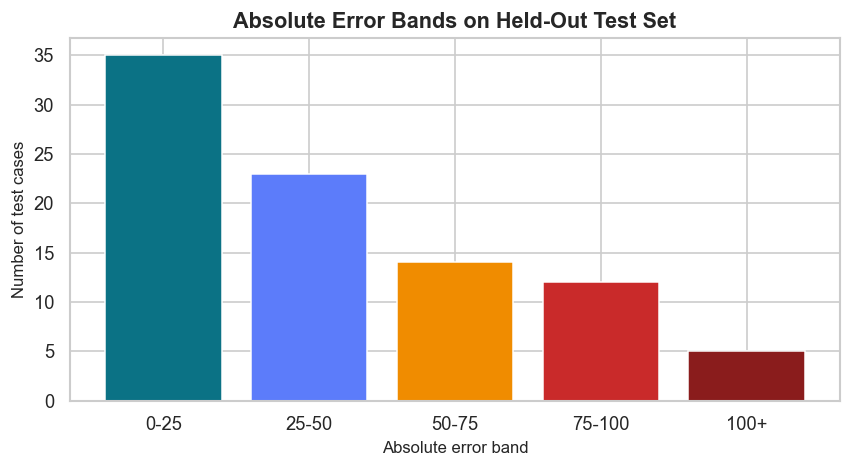

In [19]:
prediction_audit = (
    pd.DataFrame({
        "actual": y_test,
        "predicted": y_pred_selected,
        "residual": residuals,
        "absolute_error": np.abs(residuals),
    })
    .join(X_test)
    .sort_values("absolute_error", ascending=False)
)

display(prediction_audit.head(10))

error_bands = pd.cut(
    prediction_audit["absolute_error"],
    bins=[0, 25, 50, 75, 100, np.inf],
    labels=["0-25", "25-50", "50-75", "75-100", "100+"],
    include_lowest=True,
)
error_band_table = error_bands.value_counts().sort_index().to_frame("test_cases")
error_band_table["share"] = error_band_table["test_cases"] / len(prediction_audit)
display(error_band_table)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
error_colors = [
    PALETTE["teal"],
    PALETTE["indigo"],
    PALETTE["amber"],
    PALETTE["red"],
    "#8A1C1C",
]
ax.bar(
    error_band_table.index.astype(str),
    error_band_table["test_cases"],
    color=error_colors,
    edgecolor="white",
    linewidth=0.9,
)
ax.set_title("Absolute Error Bands on Held-Out Test Set")
ax.set_xlabel("Absolute error band")
ax.set_ylabel("Number of test cases")
plt.tight_layout()
plt.show()

## 12. Assignment Readiness Gauge

This table is a quick check to make sure the notebook covers the main parts expected in the assignment: problem framing, EDA, feature engineering, model comparison, evaluation, interpretation, and conclusion.

In [20]:
coverage_table = pd.DataFrame({
    "aspect": [
        "Problem framing",
        "Dataset understanding",
        "EDA and visualization",
        "Preprocessing protocol",
        "Feature engineering",
        "Model comparison",
        "Hyperparameter tuning",
        "Final test evaluation",
        "Diagnostics",
        "Interpretability",
        "Limitations and conclusion",
    ],
    "coverage": [
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
        "Complete",
    ],
    "evidence": [
        "Regression objective, target definition, research questions.",
        "Data dictionary, shape, missing-value audit, target scale.",
        "Target histogram, feature distributions, correlation heatmap, scatter plots.",
        "Train-test split, CV on training only, scaling inside pipelines.",
        "Squared terms, interactions, lipid/metabolic proxies, polynomial features.",
        "Dummy, OLS, Ridge, Lasso, ElasticNet, polynomial, Random Forest, Gradient Boosting.",
        "GridSearchCV with 5-fold KFold and RMSE scoring.",
        "Held-out RMSE, MAE, R2 reported after model selection.",
        "Actual-vs-predicted, residuals, residual distribution, Q-Q plot.",
        "Coefficients where available and permutation importance for selected model.",
        "Honest-selection note, clinical caution, small-sample limitations.",
    ],
})
display(coverage_table)

,aspect,coverage,evidence
0,Problem framing,Complete,"Regression objective, target definition, resea..."
1,Dataset understanding,Complete,"Data dictionary, shape, missing-value audit, t..."
2,EDA and visualization,Complete,"Target histogram, feature distributions, corre..."
3,Preprocessing protocol,Complete,"Train-test split, CV on training only, scaling..."
4,Feature engineering,Complete,"Squared terms, interactions, lipid/metabolic p..."
5,Model comparison,Complete,"Dummy, OLS, Ridge, Lasso, ElasticNet, polynomi..."
6,Hyperparameter tuning,Complete,GridSearchCV with 5-fold KFold and RMSE scoring.
7,Final test evaluation,Complete,"Held-out RMSE, MAE, R2 reported after model se..."
8,Diagnostics,Complete,"Actual-vs-predicted, residuals, residual distr..."
9,Interpretability,Complete,Coefficients where available and permutation i...


## 13. Research Questions

This section directly answers the six research questions from the assignment. The earlier sections show the calculations and plots, and here we summarize the answers in one place.

### Caveat for interpreting these answers

The answers below should be read as conclusions from this dataset and this train-test split, not as medical claims. Correlation and coefficients show association, not causation. Also, the test set has only 89 observations, so small RMSE differences between models should not be treated as final proof that one model is always better. For this reason, we give more importance to cross-validation performance and interpretability while choosing the final model.

In [21]:
def model_row(df, model_name):
    return df.loc[df["model"] == model_name].iloc[0]

ols_cv = model_row(cv_summary, "OLS_original")
ols_test = model_row(test_results, "OLS_original")
lasso_cv = model_row(cv_summary, "Lasso_original")
ridge_cv = model_row(cv_summary, "Ridge_original")
selected_test = model_row(test_results, selected_model_name)

expanded_families = ["feature engineered", "polynomial degree 2", "polynomial degree 3"]
expanded_cv_results = cv_summary[cv_summary["family"].isin(expanded_families)].copy()
expanded_test_results = test_results[test_results["family"].isin(expanded_families)].copy()
best_expanded_cv = expanded_cv_results.iloc[0]
best_expanded_test = expanded_test_results.iloc[0]
heldout_best_row = test_results.iloc[0]

strongest_original = corr_with_target.abs().sort_values(ascending=False).head(6).index.tolist()
strongest_original_text = ", ".join(
    f"{feature} (r={corr_with_target[feature]:.3f})" for feature in strongest_original
)

research_question_answers = pd.DataFrame([
    {
        "No.": 1,
        "Research question": "Which baseline characteristics have the strongest statistical association with disease progression?",
        "Direct answer": (
            f"The strongest original baseline associations are {strongest_original_text}. "
            f"Among engineered variables, metabolic_risk_index is strongest (r={engineered_corr.loc[0, 'correlation_with_target']:.3f})."
        ),
        "Evidence used": "Feature-target correlations, scatter plots, engineered-feature correlation chart.",
    },
    {
        "No.": 2,
        "Research question": "How well can a linear model explain the variation in the target?",
        "Direct answer": (
            f"OLS_original gives CV RMSE={ols_cv['cv_rmse_mean']:.2f}, test RMSE={ols_test['RMSE']:.2f}, "
            f"test MAE={ols_test['MAE']:.2f}, and test R2={ols_test['R2']:.3f}. This is useful but still limited explanatory power."
        ),
        "Evidence used": "OLS cross-validation row and held-out test metrics.",
    },
    {
        "No.": 3,
        "Research question": "Does regularization improve generalization when predictors are correlated?",
        "Direct answer": (
            f"Regularization improves generalization slightly and stabilizes the model under multicollinearity: "
            f"Lasso CV RMSE={lasso_cv['cv_rmse_mean']:.2f}, Ridge CV RMSE={ridge_cv['cv_rmse_mean']:.2f}, "
            f"versus OLS CV RMSE={ols_cv['cv_rmse_mean']:.2f}. The improvement is small, but VIF values for serum variables are high, so regularization is justified."
        ),
        "Evidence used": "VIF table plus OLS/Ridge/Lasso cross-validation comparison.",
    },
    {
        "No.": 4,
        "Research question": "Do nonlinear models capture relationships that a linear model cannot?",
        "Direct answer": (
            f"Expanded features do help in the held-out audit: the best expanded model by test RMSE is {best_expanded_test['model']} "
            f"with test RMSE={best_expanded_test['RMSE']:.2f} and R2={best_expanded_test['R2']:.3f}. "
            f"However, by cross-validation the best expanded model is {best_expanded_cv['model']} with CV RMSE={best_expanded_cv['cv_rmse_mean']:.2f}, "
            f"so nonlinear gains must be interpreted carefully because higher-degree features can overfit."
        ),
        "Evidence used": "Manual engineered features, degree-2 and degree-3 polynomial comparisons, held-out audit.",
    },
    {
        "No.": 5,
        "Research question": "How sensitive are the conclusions to the choice of model?",
        "Direct answer": (
            "The broad predictor story is fairly stable for BMI, s5, blood pressure, and lipid-related variables. "
            f"The exact best model is sensitive: the CV-selected model is {selected_model_name}, while the lowest held-out test RMSE appears for {heldout_best_row['model']}."
        ),
        "Evidence used": "CV ranking, test ranking, coefficient table, permutation importance.",
    },
    {
        "No.": 6,
        "Research question": "Which model provides the best balance between predictive accuracy and interpretability?",
        "Direct answer": (
            f"{selected_model_name} provides the best balance. It has the best CV RMSE ({cv_summary.loc[0, 'cv_rmse_mean']:.2f}), "
            f"good held-out performance (RMSE={selected_test['RMSE']:.2f}, R2={selected_test['R2']:.3f}), and interpretable coefficients. "
            f"{heldout_best_row['model']} has the lowest held-out test RMSE but is less straightforward to explain and was not selected by CV."
        ),
        "Evidence used": "CV-selected model, test metrics, coefficient sparsity, interpretability discussion.",
    },
])

pd.set_option("display.max_colwidth", 180)
display(research_question_answers)

,No.,Research question,Direct answer,Evidence used
0,1,Which baseline characteristics have the strongest statistical association with disease progression?,"The strongest original baseline associations are bmi (r=0.586), s5 (r=0.566), bp (r=0.441), s4 (r=0.430), s3 (r=-0.395), s6 (r=0.382). Among engineered variables, metabolic_ris...","Feature-target correlations, scatter plots, engineered-feature correlation chart."
1,2,How well can a linear model explain the variation in the target?,"OLS_original gives CV RMSE=55.39, test RMSE=53.85, test MAE=42.79, and test R2=0.453. This is useful but still limited explanatory power.",OLS cross-validation row and held-out test metrics.
2,3,Does regularization improve generalization when predictors are correlated?,"Regularization improves generalization slightly and stabilizes the model under multicollinearity: Lasso CV RMSE=55.35, Ridge CV RMSE=55.37, versus OLS CV RMSE=55.39. The improv...",VIF table plus OLS/Ridge/Lasso cross-validation comparison.
3,4,Do nonlinear models capture relationships that a linear model cannot?,"Expanded features do help in the held-out audit: the best expanded model by test RMSE is Lasso_poly2 with test RMSE=50.69 and R2=0.515. However, by cross-validation the best ex...","Manual engineered features, degree-2 and degree-3 polynomial comparisons, held-out audit."
4,5,How sensitive are the conclusions to the choice of model?,"The broad predictor story is fairly stable for BMI, s5, blood pressure, and lipid-related variables. The exact best model is sensitive: the CV-selected model is Lasso_original,...","CV ranking, test ranking, coefficient table, permutation importance."
5,6,Which model provides the best balance between predictive accuracy and interpretability?,"Lasso_original provides the best balance. It has the best CV RMSE (55.35), good held-out performance (RMSE=53.69, R2=0.456), and interpretable coefficients. Lasso_poly2 has the...","CV-selected model, test metrics, coefficient sparsity, interpretability discussion."


### Short written synthesis

1. **Strongest baseline associations:** `bmi`, `s5`, `bp`, `s4`, `s3`, and `s6` are the strongest original-feature associations with disease progression. `s3` has a negative association, while the others are positive. The engineered `metabolic_risk_index` gives the strongest single engineered association.
2. **Linear-model explanatory power:** OLS explains a useful part of the variation, but not all of it. It is clearly better than the mean baseline, but the R2 value shows that a lot of variation is still left unexplained.
3. **Regularization:** Ridge, Lasso, and ElasticNet are useful here because some serum variables are highly correlated. The improvement over OLS is not very large, but regularization makes the model more stable and easier to trust.
4. **Nonlinear relationships:** Manual engineered features and polynomial degree-2/degree-3 features can reduce the held-out test error, but cross-validation does not clearly select the most complex models as the most reliable option. So there may be nonlinear signal, but there is also overfitting risk.
5. **Sensitivity:** The main story about important predictors is fairly stable, especially for BMI, s5, blood pressure, and lipid-related variables. However, the exact best model changes depending on whether we look at CV results or the test audit.
6. **Best balance:** `Lasso_original` is our final recommended model because it has the best cross-validation result, gives good test performance, and is easier to explain than polynomial or ensemble models.

## 14. Final Conclusion

Overall, the diabetes progression target has a clear but not perfect linear signal. BMI, `s5`, blood pressure, and cholesterol-related variables appear important throughout the analysis. The VIF results also show that some serum variables are strongly correlated, so regularized regression is a sensible choice.

The final recommendation is based on cross-validation rather than simply picking the model with the lowest test error. `Lasso_original` is a good balance because it performs well and remains interpretable. The polynomial models are useful to compare, but they are more complex and their improvement is not consistent enough in cross-validation.

So, this notebook covers the main assignment requirements: EDA, feature engineering, model comparison, regularization, final evaluation, diagnostics, interpretation, and the direct answers to the research questions.

In [22]:
selected_test_row = test_results.loc[test_results["model"] == selected_model_name].iloc[0]
heldout_best_row = test_results.iloc[0]

inline_summary = pd.DataFrame([
    {"item": "Observations", "value": int(X.shape[0])},
    {"item": "Original features", "value": int(X.shape[1])},
    {"item": "Engineered features considered", "value": int(X_engineered.shape[1])},
    {"item": "CV-selected model", "value": selected_model_name},
    {"item": "CV RMSE of selected model", "value": f"{cv_summary.loc[cv_summary['model'] == selected_model_name, 'cv_rmse_mean'].iloc[0]:.2f}"},
    {"item": "Selected model test RMSE", "value": f"{selected_test_row['RMSE']:.2f}"},
    {"item": "Selected model test MAE", "value": f"{selected_test_row['MAE']:.2f}"},
    {"item": "Selected model test R2", "value": f"{selected_test_row['R2']:.3f}"},
    {"item": "Lowest held-out test RMSE model", "value": heldout_best_row["model"]},
    {"item": "Lowest held-out test RMSE", "value": f"{heldout_best_row['RMSE']:.2f}"},
])

display(Markdown("**Inline-only final summary:** no charts, CSV files, or JSON files are saved outside this notebook."))
display(inline_summary)

**Inline-only final summary:** no charts, CSV files, or JSON files are saved outside this notebook.

,item,value
0,Observations,442
1,Original features,10
2,Engineered features considered,19
3,CV-selected model,Lasso_original
4,CV RMSE of selected model,55.35
5,Selected model test RMSE,53.69
6,Selected model test MAE,42.82
7,Selected model test R2,0.456
8,Lowest held-out test RMSE model,Lasso_poly2
9,Lowest held-out test RMSE,50.69
